# Single-site traces

author: laquitainesteeve@gmail.com

Plot single-electrode voltage traces

Execution time: 20 min

Tested on Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz)

Resources required:
- 180 GB RAM

## Setup

Prerequisites:

1. Setup "_envs/spikebias.yml_" virtual environment
2. Setup jupyter kernel _$python -m ipykernel install --user --name spikebias --display-name "spikebias"_
3. Download recordings: "_notebooks/0_download_recordings.ipynb_"


In [1]:
# setup packages
%load_ext autoreload
%autoreload 2
import os
from os.path import join
import numpy as np
from matplotlib import pyplot as plt
import spikeinterface as si
from spikeinterface import preprocessing as spre
import yaml
import warnings
import matplotlib as mpl
import pandas as pd

# turn off warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")
print("Spikeinterface:", si.__version__)

# move to project path
proj_path = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(proj_path)

# spikebias package
from src.nodes.validation import noise

# SETUP PARAMETERS
FREQ_MIN = 300         # high-pass filtering cutoff frequency
REC_DURATION_SEC = 600 # duration of recording examined
LAYER = "L5"           # layer 5
DURATION = 1.01        # period examined in figure
SF_dense = 20000       # sampling frequency of dense biophy model

GAIN_TO_UV = 0.195

# dense biophy dense probe model
RAW_PATH_d2 = "dataset/00_raw/recording_dense_probe2"

# setup figure parameters
COMPUTE_FIG_DATA = True
SAVE_FIG_DATA = True
LOAD_FIG_DATA = False
SAVE_FIG = True

# get paths of saved figures
with open(join(proj_path, "conf/figures.yml"), "r", encoding="utf-8") as yaml_file:
    fig_data_paths = yaml.load(yaml_file, Loader=yaml.FullLoader)

# figure settings
FIG_SIZE = (0.9, 0.7)

# colors
COLOR_HS = np.array([26, 152, 80]) / 255

# axes
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5 
plt.rcParams["xtick.minor.width"] = 0.5 
plt.rcParams["ytick.major.width"] = 0.5 
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# keeps text as text in saved svg
mpl.rcParams['svg.fonttype'] = 'none' 

# legend
savefig_cfg = {"transparent":True, "dpi":300}
legend_cfg = {"frameon": False, "handletextpad": 0.1}
tight_layout_cfg = {"pad": 0.5}
LG_FRAMEON = False              # no legend frame

Spikeinterface: 0.100.8


In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Clear RAM

In [3]:
# (commented out: asks for the sudo password to clear the RAM cache, which blocks unattended runs)
# import getpass; password = getpass.getpass("Enter your sudo password: ")
# !sync; echo {password} | sudo -S sh -c 'echo 1 > /proc/sys/vm/drop_caches'

## Denser probe

### Compute

In [4]:
%%time

# setup parameters
ID_PERIOD_SILI = 10
L5_SITE = 10
REC_DURATION_SEC = 600
LAYER = "L5"

# compute figure data
if COMPUTE_FIG_DATA:

    # load raw recording extractors
    Rec = si.load_extractor(RAW_PATH_d2)

    # set gain to uV (0.195 described in https://doi.org/10.1038/s41597-021-00970-3)
    Rec.set_channel_gains(GAIN_TO_UV)
    print("gain:", Rec.get_channel_gains())

    # get metadata
    sfreq = Rec.get_sampling_frequency()
    layers = Rec.get_property("layers")
    site = np.where(layers == LAYER)[0][L5_SITE]

    # extract first 10 min of the recording extractors 
    Rec = Rec.frame_slice(start_frame=0, end_frame=REC_DURATION_SEC*sfreq)
    print("Recording:", Rec)

    # preprocess voltage traces
    Rec = spre.astype(Rec, "int16")
    Rec = spre.highpass_filter(Rec, freq_min=FREQ_MIN)
    Rec = spre.common_reference(Rec, reference="global", operator="median")

    # select a site and period
    one_sec_period = np.arange((ID_PERIOD_SILI - 1) * sfreq, ID_PERIOD_SILI * sfreq, 1)
    traces = Rec.get_traces(channel_ids=[str(site)])
    traces = traces * GAIN_TO_UV

    # plot figure
    fig_data = traces[one_sec_period.astype(int)]

# save figure data
if SAVE_FIG_DATA:
    
    wind_end = int(np.floor(len(traces)/sfreq))
    bkg_noise = noise.measure_trace_noise(traces[one_sec_period.astype(int)], int(sfreq), wind_end)
    np.save(fig_data_paths["fig2d_compo_silico_horv_bkg_noise"], bkg_noise)    
    np.save(fig_data_paths["fig2d_compo_silico_horv"], fig_data)

# load figure data
elif LOAD_FIG_DATA:
    
    bkg_noise = np.load(fig_data_paths["fig2d_compo_silico_horv_bkg_noise"])    
    fig_data = np.load(join(proj_path, fig_data_paths["fig2d_compo_silico_horv"]))
    print("loaded figure data")
    print("nb of 1-sec windows:", len(bkg_noise))
    print("Background noise level (min MAD over windows):", min(bkg_noise))

gain: [0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195
 0.195 0.195 0.195 0.195 0.195 0.195 0.195 0.195]
Recording: FrameSliceRecording: 128 channels - 20.0kHz - 1 segments - 12,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 5.72 GiB


CPU times: user 33.1 s, sys: 3.91 s, total: 37.1 s
Wall time: 37.1 s


### Plot

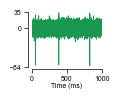

In [5]:
# plot (size of the panel in the figure, see src/nodes/validation/single_site_plots.py)
from src.nodes.validation import single_site_plots

t_ms = np.arange(len(fig_data)) / (SF_dense / 1000)
fig = single_site_plots.plot_single_site_trace(t_ms, fig_data, COLOR_HS, yticks=(-84, 0, 35))

# save figure
if SAVE_FIG:
    fig.savefig("figures/8_source_data/fig2f/fig2f.svg", transparent=True)      # also saves the .pdf (figure_style)

### Save source data file

In [6]:
# time
time_ms = np.linspace(0, 1000, SF_dense, endpoint=True)

# save to Excel
df = pd.DataFrame({"time_ms": time_ms, "signal": fig_data.flatten()})
df.to_excel("figures/8_source_data/fig2f/fig2f.xlsx", index=False)